<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/acceleration_hodograph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simple Pendulum Acceleration Hodograph.

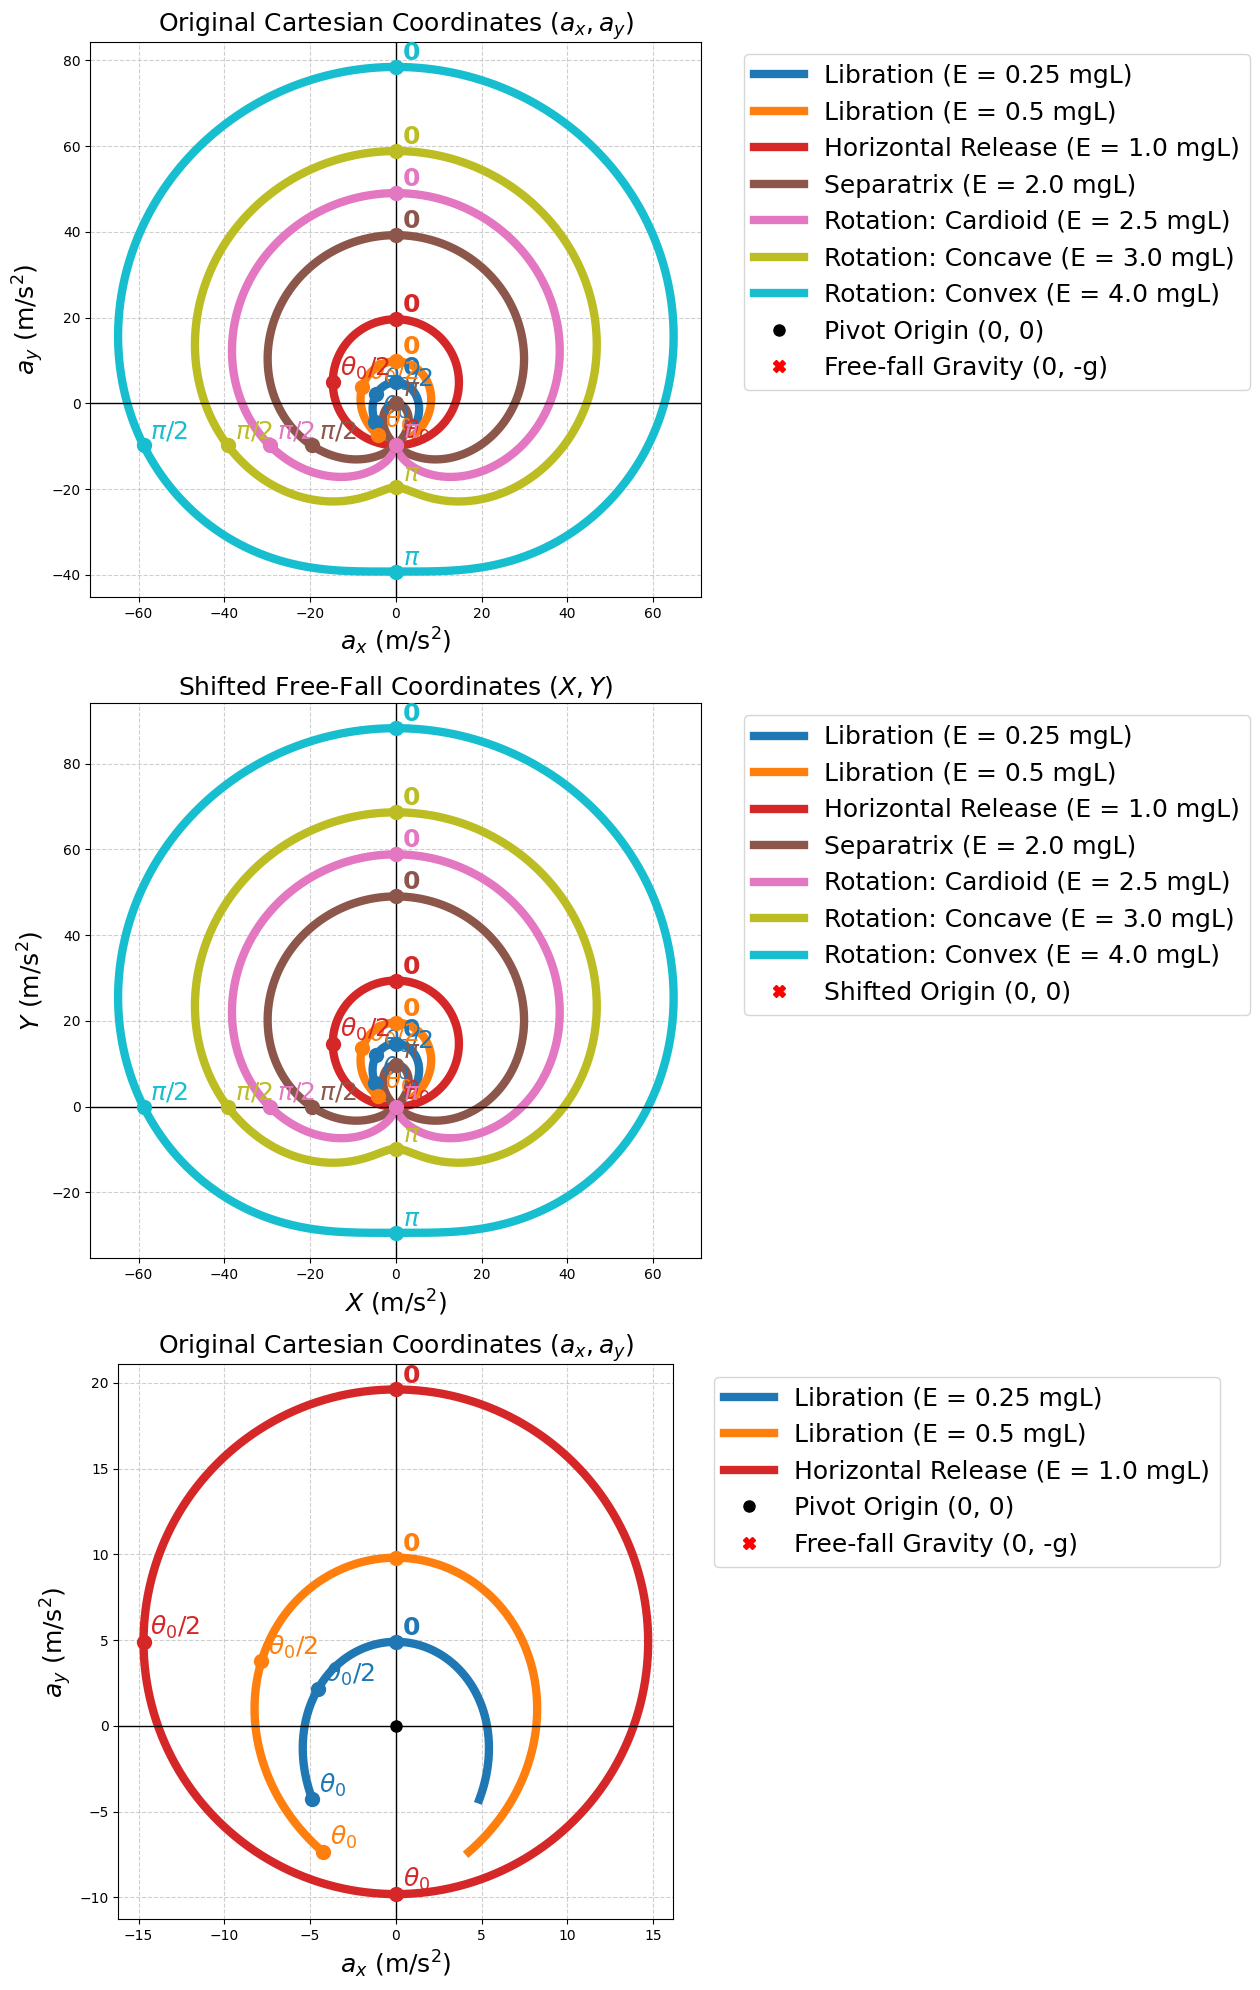

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# System constants
g = 9.81  # Acceleration due to gravity (m/s^2)
m = 1.0   # Mass of the pendulum bob (kg)
L = 1.0   # Length of the pendulum string/rod (m)

def calculate_acceleration_locus(E):
    """
    Calculates the acceleration vector coordinates based on total energy.
    Also returns 3 marker points and their angle labels for plotting.
    """
    # Energy-dependent base radius parameter
    C = (2 * E) / (m * L) - 2 * g

    # Determine the physical bounds and marker points based on the regime
    if E < 2 * m * g * L:
        # Libration (oscillation): angle is bounded by the initial release height
        theta_0 = np.arccos(1 - E / (m * g * L))
        theta = np.linspace(-theta_0, theta_0, 1000)

        # Markers: Bottom, Half-angle, and Release angle
        marker_angles = [0, theta_0/2, theta_0]
        marker_labels = ['0', r'$\theta_0/2$', r'$\theta_0$']
    else:
        # Separatrix and Rotation: pendulum completes full circles
        theta = np.linspace(-np.pi, np.pi, 1000)

        # Markers: Bottom, Horizontal, and Top
        marker_angles = [0, np.pi/2, np.pi]
        marker_labels = ['0', r'$\pi/2$', r'$\pi$']

    # Original Cartesian coordinates (ax, ay)
    # Using the convention where positive y is directed upward (opposite gravity)
    ax = -C * np.sin(theta) - 3 * g * np.sin(theta) * np.cos(theta)
    ay = -g + C * np.cos(theta) + 3 * g * np.cos(theta)**2

    # Shifted coordinates (X, Y) transforming to the free-fall reference frame
    X = ax
    Y = ay + g

    # Calculate specific coordinates for the markers
    m_ax = -C * np.sin(marker_angles) - 3 * g * np.sin(marker_angles) * np.cos(marker_angles)
    m_ay = -g + C * np.cos(marker_angles) + 3 * g * np.cos(marker_angles)**2
    m_X = m_ax
    m_Y = m_ay + g

    return ax, ay, X, Y, m_ax, m_ay, m_X, m_Y, marker_labels

# Define specific energy levels to map the different topological regimes
energies = {
    'Libration (E = 0.25 mgL)': 0.25 * m * g * L,
    'Libration (E = 0.5 mgL)': 0.5 * m * g * L,
    'Horizontal Release (E = 1.0 mgL)': 1.0 * m * g * L,
    'Separatrix (E = 2.0 mgL)': 2.0 * m * g * L,
    'Rotation: Cardioid (E = 2.5 mgL)': 2.5 * m * g * L,
    'Rotation: Concave (E = 3.0 mgL)': 3.0 * m * g * L,
    'Rotation: Convex (E = 4.0 mgL)': 4.0 * m * g * L
}

# Set up the visualization
fig, (plot_orig, plot_shift, plot_libration) = plt.subplots(3, 1, figsize=(20, 20))
colors = plt.cm.tab10(np.linspace(0, 1, len(energies)))

# Iterate through the energy regimes and plot each curve with its markers
for (label, E), color in zip(energies.items(), colors):
    ax, ay, X, Y, m_ax, m_ay, m_X, m_Y, m_labels = calculate_acceleration_locus(E)
    # Plot the continuous locus lines
    plot_orig.plot(ax, ay, label=label, color=color, linewidth=6)
    plot_shift.plot(X, Y, label=label, color=color, linewidth=6)
    if 'Rotation' not in label and 'Separatrix' not in label:
        plot_libration.plot(ax, ay, label=label, color=color, linewidth=6)
    # Scatter plot the specific angle dots
    plot_orig.scatter(m_ax, m_ay, color=color, s=100, zorder=5)
    plot_shift.scatter(m_X, m_Y, color=color, s=100, zorder=5)
    if 'Rotation' not in label and 'Separatrix' not in label:
        plot_libration.scatter(m_ax, m_ay, color=color, s=100, zorder=5)
    # Add text labels next to the dots
    for i, txt in enumerate(m_labels):
        plot_orig.annotate(txt, (m_ax[i], m_ay[i]), textcoords="offset points",
                           xytext=(5, 5), fontsize=18, color=color, fontweight='bold')
        plot_shift.annotate(txt, (m_X[i], m_Y[i]), textcoords="offset points",
                            xytext=(5, 5), fontsize=18, color=color, fontweight='bold')
        if 'Rotation' not in label and 'Separatrix' not in label:
            plot_libration.annotate(txt, (m_ax[i], m_ay[i]), textcoords="offset points",
                           xytext=(5, 5), fontsize=18, color=color, fontweight='bold')

# Format the Original Coordinates Plot (ax, ay)
plot_orig.set_title('Original Cartesian Coordinates ($a_x, a_y$)',fontsize=18)
plot_orig.set_xlabel('$a_x$ (m/s$^2$)', fontsize=18)
plot_orig.set_ylabel('$a_y$ (m/s$^2$)', fontsize=18)
plot_orig.axhline(0, color='black', linewidth=1)
plot_orig.axvline(0, color='black', linewidth=1)
plot_orig.plot(0, 0, 'ko', markersize=8, label='Pivot Origin (0, 0)')
plot_orig.plot(0, -g, 'rX', markersize=8, label='Free-fall Gravity (0, -g)')
plot_orig.set_aspect('equal')
plot_orig.grid(True, linestyle='--', alpha=0.6)
plot_orig.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=18)

# Format the Shifted Coordinates Plot (X, Y)
plot_shift.set_title('Shifted Free-Fall Coordinates ($X, Y$)',fontsize=18)
plot_shift.set_xlabel('$X$ (m/s$^2$)', fontsize=18)
plot_shift.set_ylabel('$Y$ (m/s$^2$)', fontsize=18)
plot_shift.axhline(0, color='black', linewidth=1)
plot_shift.axvline(0, color='black', linewidth=1)
plot_shift.plot(0, 0, 'rX', markersize=8, label='Shifted Origin (0, 0)')
plot_shift.set_aspect('equal')
plot_shift.grid(True, linestyle='--', alpha=0.6)
plot_shift.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=18)

# Format the Original Coordinates Plot (ax, ay)
plot_libration.set_title('Original Cartesian Coordinates ($a_x, a_y$)',fontsize=18)
plot_libration.set_xlabel('$a_x$ (m/s$^2$)', fontsize=18)
plot_libration.set_ylabel('$a_y$ (m/s$^2$)', fontsize=18)
plot_libration.axhline(0, color='black', linewidth=1)
plot_libration.axvline(0, color='black', linewidth=1)
plot_libration.plot(0, 0, 'ko', markersize=8, label='Pivot Origin (0, 0)')
plot_libration.plot(0, -g, 'rX', markersize=8, label='Free-fall Gravity (0, -g)')
plot_libration.set_aspect('equal')
plot_libration.grid(True, linestyle='--', alpha=0.6)
plot_libration.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=18)


plt.tight_layout()
plt.show()